![Banner](../../../../Images/Banner/07_remote_sensing/09_12_surface_energy_balance_modeling.png)

# Capstone: Water Use of Boro Rice in Bangladesh

Boro is the dry season rice of Bangladesh: transplanted from late December to February, harvested
in April and May, and grown almost entirely on groundwater pumped by shallow and deep tubewells. It
produces more than half of the country's rice, and it is also the main reason groundwater levels in
the north and centre of the country fall every dry season. How much of the pumped water does the
crop actually consume as ET, and how much returns to the aquifer by percolation? This capstone
answers the first half of that question for Trishal and Bhaluka upazilas of Mymensingh district,
with the tools of the chapter: map the Boro fields from their flooding and green-up, run METRIC and
SSEBop on every clear Landsat image of the 2023-24 season, accumulate seasonal ET, and convert it
to a volume of water.

## Overview

### The question

- Where were Boro rice fields in the 2023-24 season, and how large an area did they cover?
- How much water did they consume (ET) from transplanting to harvest, per hectare and in total?
- Do two models with different assumptions (METRIC and SSEBop) agree, and how do the satellite crop
  coefficients compare with FAO-56 values for rice?

### What changes from the California site

| | Westside San Joaquin Valley | Mymensingh |
|---|---|---|
| Climate | arid summer, very dry air | humid subtropics; the Boro season is the dry, sunny part of the year |
| Fields | 20 to 60 ha | 0.05 to 0.5 ha: many 30 m pixels are mixtures |
| Cold anchor | full-cover orchards and row crops | flooded, full-cover rice in March; homestead trees |
| Hot anchor | fallow fields at 60 C | homesteads, roads, dry fallow; much cooler |
| Water | sprinklers and drip | standing water in the paddies from transplanting to grain filling |
| Ground data | crop map (CDL) | none; rice is mapped from the images |

Standing water makes rice a special case: paddy ET is close to open-water evaporation early in the
season, soil heat flux behaves like that of water, and the surface may be cooler than any
vegetation. In the humid tropics the contrast between anchors is also small, which makes the
calibration more sensitive.

### Mapping rice from its flooding

Transplanted rice fields are flooded before and during transplanting, so for a few weeks they look
like water mixed with young plants. Xiao et al. (2005, 2006) used this: a pixel is flooded when the
land surface water index `LSWI = (NIR - SWIR1) / (NIR + SWIR1)` exceeds the vegetation index. A
pixel that was flooded during transplanting and then turned green (high NDVI) in March is Boro rice.

## The Workflow with GeoLattice

| Step | Tools |
|---|---|
| Scenes, land cover, weather | `sd.load_scene` (8 Landsat scenes, WorldCover, ERA5), `sd.daily_reference` |
| Rice map | NDVI, LSWI, WorldCover cropland |
| Hot anchor after rain | FAO-56 soil evaporation (notebook 10) |
| ET models | `sd.energy_inputs`, `seb.run_metric`, `seb.run_ssebop` |
| Season | `seb.interpolate_etrf`, `seb.seasonal_et`, `seb.zonal_et` |

### Learning objectives

1. Adapt the chapter's chain to a humid, smallholder rice landscape without a crop map.
2. Map Boro rice from flooding and green-up signals.
3. Calibrate METRIC on each image and check its anchors in a low-contrast scene.
4. Accumulate seasonal ET of rice with METRIC and SSEBop and compare them.
5. Turn seasonal ET into a water volume and discuss what it means for groundwater.

### Data

| Dataset | Content |
|---|---|
| Landsat 8 and 9 C2 L2, path 137 row 43 | 8 scenes from 20 December 2023 to 26 April 2024 over 90.20 to 90.50 E, 24.30 to 24.60 N (about 30 x 33 km) |
| ESA WorldCover 2021 | 10 m land cover, cropland class, mode-resampled to 30 m |
| Copernicus DEM GLO-30 | elevation |
| ERA5 hourly and daily (Open-Meteo) | weather at each overpass, daily reference ET and rain |

The scenes are cached under `Data/08_remote_sensing/08_12_surface_energy_balance/mymensingh/`
(about 240 MB; notebook 01's helper builds them on first use).

### Contents

- Setup
- The season in images
- Mapping Boro rice
- Reference ET and rain
- METRIC on every image
- SSEBop on every image
- Seasonal ET of Boro rice
- Crop coefficients of rice
- From millimetres to water volume
- Discussion
- Summary and exercises

## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor)
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.rsense.surface_energy_balance as seb  # energy balance and ET models
import seb_data as sd  # chapter helper: downloads, caches and loads the scenes

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
OUT = Path("outputs")  # results written by this chapter
OUT.mkdir(exist_ok=True)  # create it if needed
print("GeoLattice", geolattice.__version__, "| data folder", sd.DATA.relative_to(sd.DATA.parents[3]))  # versions and paths

SITE = sd.MYMENSINGH  # Trishal and Bhaluka, Mymensingh district
SCENES = sd.BORO_2024  # 8 Landsat scenes, December 2023 to April 2024
stacks = {pd.Timestamp(s.attrs["datetime"]).normalize(): s for s in map(sd.load_scene, SCENES)}  # cached stacks by date
dates = list(stacks)  # image dates
first = stacks[dates[0]]  # grid and land cover
print(f"{len(dates)} scenes, {dates[0]:%d %b %Y} to {dates[-1]:%d %b %Y}; grid {dict(first.sizes)}; CRS {first.rio.crs}")  # what was loaded

GeoLattice 0.3.49 | data folder GeoLattice/Data/08_remote_sensing/08_12_surface_energy_balance


8 scenes, 20 Dec 2023 to 26 Apr 2024; grid {'y': 1127, 'x': 1035}; CRS EPSG:32646


## The season in images

The clear share of each image, the weather at the overpass, and the median NDVI and LSWI of the
cropland pixels trace the season: puddling and flooding in January and February, green-up in March,
ripening in April.

,clear %,air C,RH %,cropland NDVI,cropland LSWI,flooded cropland %
date,,,,,,
2023-12-20,99.9,22.4,68,0.43,0.10,15.41
2023-12-28,100.0,23.8,66,0.43,0.12,18.23
2024-01-29,87.0,19.6,67,0.32,0.31,54.01
2024-03-01,100.0,26.2,49,0.59,0.28,10.29
2024-03-09,100.0,26.9,38,0.66,0.29,6.43
2024-03-17,69.0,29.2,54,0.71,0.33,3.98
2024-04-02,100.0,33.4,45,0.71,0.35,2.64
2024-04-26,99.9,35.1,56,0.56,0.22,3.22


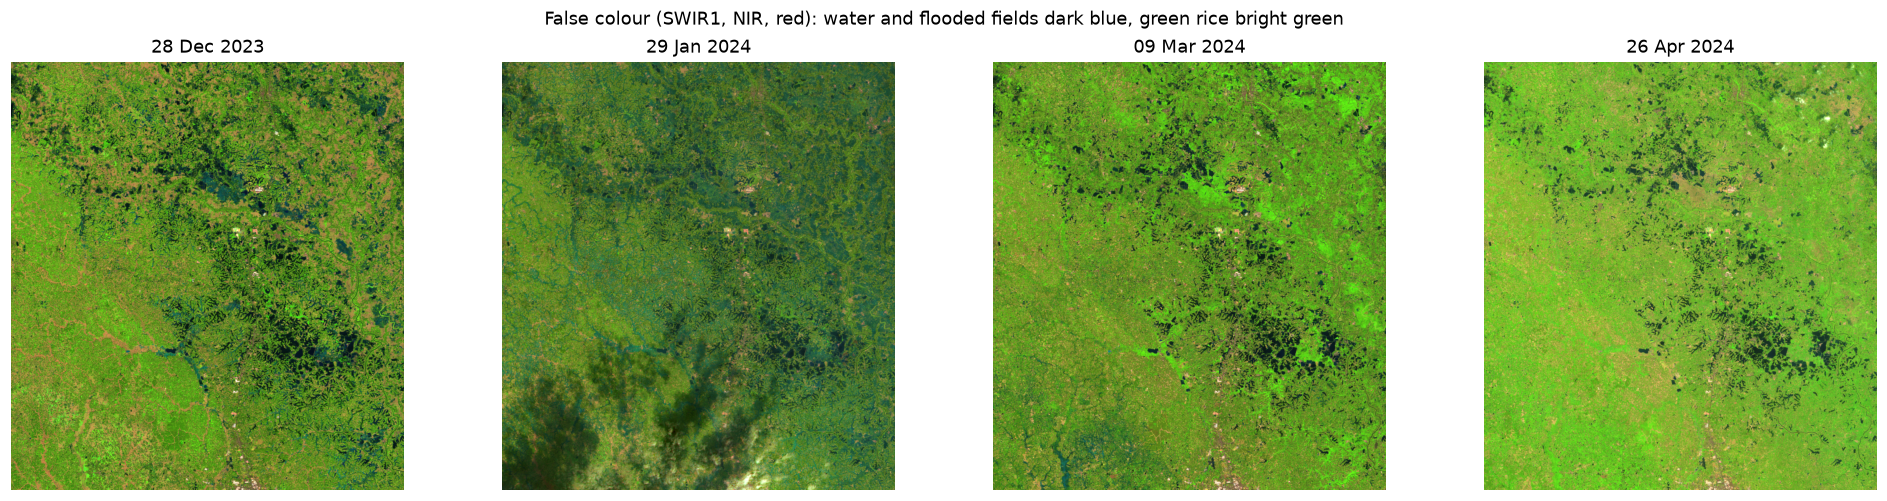

In [2]:
crop = first.worldcover == 40  # WorldCover cropland
rows = []  # one row per image
for d, s in stacks.items():  # every image
    m = s.clear.astype(bool)  # clear pixels
    ndvi = seb.ndvi(s.red, s.nir).where(m & crop)  # NDVI of cropland
    lswi = ((s.nir - s.swir16) / (s.nir + s.swir16)).where(m & crop)  # land surface water index
    rows.append({"date": d.date(), "clear %": round(100 * float(m.mean()), 1), "air C": round(s.attrs["t_air_c"], 1),
                 "RH %": round(s.attrs["rh"]), "cropland NDVI": float(ndvi.median()), "cropland LSWI": float(lswi.median()),
                 "flooded cropland %": 100 * float(((lswi + 0.05) >= ndvi).sum() / ndvi.notnull().sum())})  # summary
season_tab = pd.DataFrame(rows).set_index("date")  # table
display(season_tab.round(2))  # the season
fig, ax = plt.subplots(1, 4, figsize=(18, 4.6))  # four dates
for a_, d in zip(ax, [dates[1], dates[2], dates[4], dates[-1]]):  # late December, late January, early March, late April
    s = stacks[d]  # its stack
    a_.imshow(np.clip(np.dstack([s.swir16, s.nir, s.red]) * 2.5, 0, 1)); a_.set_title(f"{d:%d %b %Y}"); a_.axis("off")  # false colour
plt.suptitle("False colour (SWIR1, NIR, red): water and flooded fields dark blue, green rice bright green"); plt.tight_layout(); plt.show()  # draw

The flooded share of cropland peaks on 29 January (54 %), when most Boro fields have been puddled
and transplanted, and the cropland NDVI peaks in mid-March and early April (0.71). The false colour images show the same
progression: dark, water-filled fields in January turning bright green by March. By late April the
first fields are ripening.

## Mapping Boro rice

A Boro pixel is WorldCover cropland, was flooded (`LSWI + 0.05 >= NDVI`) on at least one image from
late December to early February, and reached NDVI of at least 0.6 on at least one image in March or
April.

cropland 45,006 ha | flooded at transplanting 24,039 ha | Boro rice 20,614 ha (46 % of cropland)


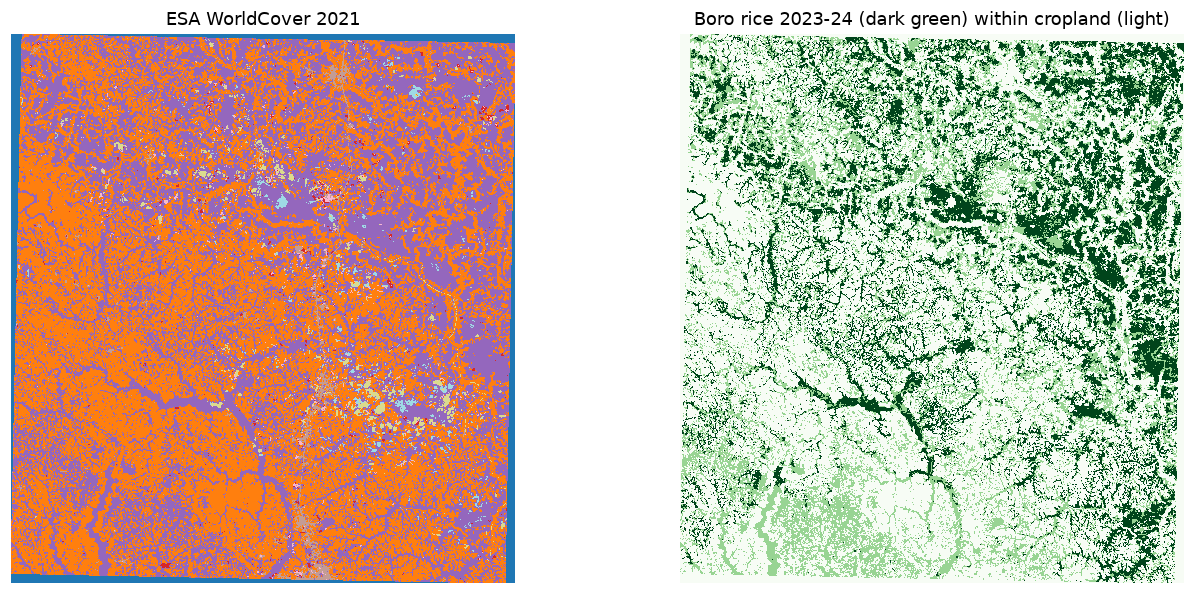

In [3]:
def lswi_ndvi(s):  # LSWI and NDVI of a stack, clouds masked
    m = s.clear.astype(bool)  # clear pixels
    return ((s.nir - s.swir16) / (s.nir + s.swir16)).where(m), seb.ndvi(s.red, s.nir).where(m)  # indices


flood = xr.zeros_like(first.red, dtype=bool)  # flooded at transplanting
for d in [d for d in dates if d <= pd.Timestamp("2024-02-10")]:  # transplanting images
    l_, n_ = lswi_ndvi(stacks[d])  # indices
    flood = flood | ((l_ + 0.05) >= n_).fillna(False)  # flooded on this date
green = xr.concat([lswi_ndvi(stacks[d])[1] for d in dates if d >= pd.Timestamp("2024-03-01")], "time").max("time")  # peak NDVI, March to April
rice = crop & flood & (green >= 0.6)  # Boro rice
area_ha = float(rice.sum()) * 900 / 1e4  # ha
print(f"cropland {float(crop.sum()) * 900 / 1e4:,.0f} ha | flooded at transplanting {float((crop & flood).sum()) * 900 / 1e4:,.0f} ha | "
      f"Boro rice {area_ha:,.0f} ha ({100 * float(rice.sum() / crop.sum()):.0f} % of cropland)")  # areas
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))  # two maps
ax[0].imshow(first.worldcover, cmap="tab20", interpolation="nearest"); ax[0].set_title("ESA WorldCover 2021"); ax[0].axis("off")  # land cover
ax[1].imshow(np.where(rice, 1.0, np.where(crop, 0.4, 0.0)), cmap="Greens", vmin=0, vmax=1, interpolation="nearest")  # rice map
ax[1].set_title("Boro rice 2023-24 (dark green) within cropland (light)"); ax[1].axis("off"); plt.tight_layout(); plt.show()  # draw

Nearly half of the WorldCover cropland (46 %, about 20,600 ha) was mapped as Boro rice. The rest
includes vegetables, mustard, fallow land and cropland too mixed with homesteads, bunds and trees to
pass the flood and green-up tests, which is common where fields are this small; 24,000 ha were
flooded at transplanting but not all of them turned green enough. The map has not been checked
against field data, so the area is an estimate; the Department of Agricultural Extension publishes
Boro areas by upazila for a check.

## Reference ET and rain

The Boro season is the dry, sunny part of the year: rain is rare from December to March and the
alfalfa reference ET rises from about 2 to over 6 mm a day as the days lengthen and warm. The hot
anchor's ETrF after rain comes from the FAO-56 soil evaporation balance of notebook 10.

rain from 15 January to 30 April: 69 mm | alfalfa reference ET: 568 mm | grass reference ET: 445 mm


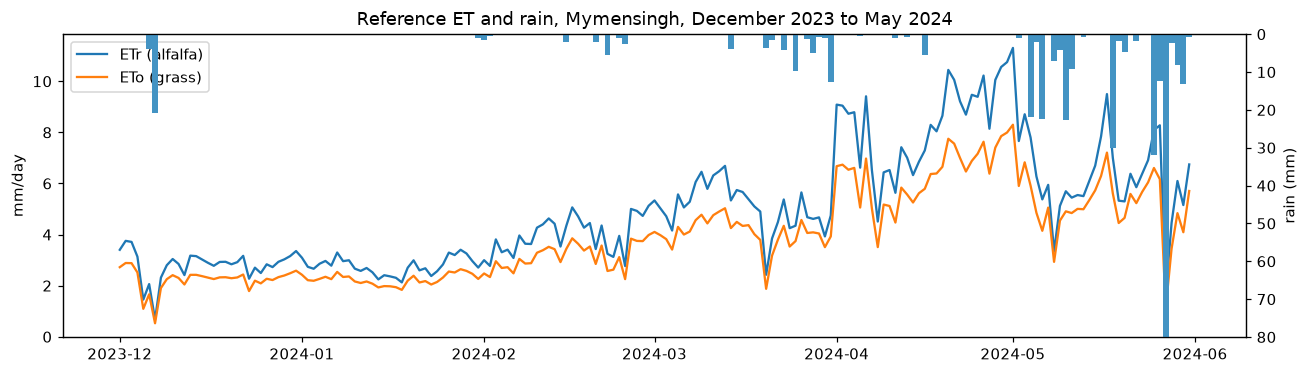

,ETrF_hot (Ke on the image date)
time,
2023-12-20,0.16
2023-12-28,0.04
2024-01-29,0.00
2024-03-01,0.08
2024-03-09,0.00
2024-03-17,0.07
2024-04-02,0.35
2024-04-26,0.00


In [4]:
ref = sd.daily_reference(SITE, "2023-12-01", "2024-05-31", z=15.0)  # daily ETr, ETo and rain, ERA5
rain = ref["precip"]  # mm/day


def soil_evaporation_ke(rain, etr, tew=25.0, rew=9.0, ke_max=1.0):  # FAO-56 two-stage evaporation of bare soil (notebook 10)
    de, out = tew, []  # start dry
    for p_, e_ in zip(rain.values, etr.values):  # day by day
        de = max(de - p_, 0.0)  # rain refills the layer
        kr = 1.0 if de <= rew else max((tew - de) / (tew - rew), 0.0)  # stage 1 or 2
        de = min(de + kr * ke_max * e_, tew)  # evaporation
        out.append(kr * ke_max)  # Ke
    return pd.Series(out, index=rain.index)  # daily Ke


ke = soil_evaporation_ke(rain, ref["etr"])  # Ke of bare soil
print(f"rain from 15 January to 30 April: {rain.loc['2024-01-15':'2024-04-30'].sum():.0f} mm | "
      f"alfalfa reference ET: {ref['etr'].loc['2024-01-15':'2024-04-30'].sum():.0f} mm | grass reference ET: {ref['eto'].loc['2024-01-15':'2024-04-30'].sum():.0f} mm")  # season totals
fig, ax = plt.subplots(figsize=(12, 3.5)); ax.plot(ref["etr"], label="ETr (alfalfa)"); ax.plot(ref["eto"], label="ETo (grass)")  # reference ET
ax2 = ax.twinx(); ax2.bar(rain.index, rain, color="#4393c3", width=1); ax2.set_ylim(80, 0); ax2.set_ylabel("rain (mm)")  # rain
ax.set_ylabel("mm/day"); ax.legend(loc="upper left"); ax.set_title("Reference ET and rain, Mymensingh, December 2023 to May 2024"); plt.tight_layout(); plt.show()  # draw
ke.reindex(dates).round(2).to_frame("ETrF_hot (Ke on the image date)")  # hot anchor's ETrF

## METRIC on every image

The chain of notebook 06 runs on each image, with the hot anchor's ETrF from the balance above.
The anchor table is the first thing to check in a humid scene: the contrast between the anchors is
much smaller than in California.

In [5]:
etrf_layers, rows, fc_layers = [], [], []  # results
for d, s in stacks.items():  # every image
    q = sd.energy_inputs(s)  # inputs and automated anchors
    r = seb.run_metric(q["lst"], q["rn"], q["g"], q["zom"], q["u200"], q["pressure"], q["etr_inst"], anchors=q["anchors"],
                       etrf_hot=float(ke.get(d, 0.0)), etr_daily=q["etr_daily"])  # METRIC
    etrf_layers.append(r.etrf.where(q["mask"]).expand_dims(time=[d]))  # ETrF
    fc_layers.append(seb.fractional_cover(q["ndvi"]).where(q["mask"]).expand_dims(time=[d]))  # vegetation cover
    rows.append({"date": d.date(), "cold NDVI": q["anchors"]["cold"]["ndvi"], "cold LST (C)": q["anchors"]["cold"]["lst"] - 273.15,
                 "hot NDVI": q["anchors"]["hot"]["ndvi"], "hot LST (C)": q["anchors"]["hot"]["lst"] - 273.15,
                 "contrast (K)": q["anchors"]["hot"]["lst"] - q["anchors"]["cold"]["lst"], "ETr24 (mm)": q["etr_daily"],
                 "rice ETrF median": float(r.etrf.where(rice).median())})  # calibration log
etrf = xr.concat(etrf_layers, "time")  # (time, y, x)
fc = xr.concat(fc_layers, "time")  # (time, y, x)
pd.DataFrame(rows).set_index("date").round(2)  # one row per image

,cold NDVI,cold LST (C),hot NDVI,hot LST (C),contrast (K),ETr24 (mm),rice ETrF median
date,,,,,,,
2023-12-20,0.87,24.09,0.26,27.73,3.64,2.84,0.35
2023-12-28,0.84,25.82,0.26,29.25,3.43,2.93,0.54
2024-01-29,0.71,19.89,0.22,22.44,2.55,3.26,0.69
2024-03-01,0.85,26.13,0.28,33.12,6.98,5.34,0.80
2024-03-09,0.86,25.67,0.20,33.93,8.26,6.46,0.95
2024-03-17,0.83,28.07,0.26,36.52,8.45,5.38,0.85
2024-04-02,0.78,30.39,0.25,40.50,10.12,9.05,1.02
2024-04-26,0.78,32.57,0.25,41.69,9.12,10.22,0.87


The anchors are only 2.5 to 10 K apart, against 25 K on the Westside in July, and on 29 January
just 2.6 K: each kelvin of LST matters several times more here, and an unrepresentative anchor can
shift the whole image. In December, before the rice was planted, the cold anchors (NDVI 0.84 to
0.87) can only be trees, most likely homestead groves; from March on, dense rice competes with them.
The median rice ETrF rises from 0.69 on 29 January to 0.95 to 1.02 in March and early April, when
the fields are flooded and green, and falls to 0.87 as they ripen.

## SSEBop on every image

SSEBop needs no anchors: its cold limit is `c Tmax` with `c` from the image's dense vegetation, and
its hot limit is set by the clear-sky net radiation of the day (notebook 07).

In [6]:
d_ref = sd.weather(SITE, "2023-12-01", "2024-05-31")["daily"]  # ERA5 daily weather
etf_layers = []  # SSEBop ET fractions
for d, s in stacks.items():  # every image
    q = sd.energy_inputs(s)  # inputs
    day = d_ref.loc[d]  # that day's weather
    tmax_k = day.temperature_2m_max + 273.15  # K
    tc, c = seb.cold_reference_temperature(q["lst"], q["ndvi"], tmax_k, ndvi_min=0.6)  # cold limit
    ra = float(seb.extraterrestrial_radiation_daily(SITE["lat"], d.day_of_year)); rso = (0.75 + 2e-5 * q["z"]) * ra  # MJ m-2 d-1
    ea_d = float(seb.actual_vapour_pressure(t_dew_c=day.dew_point_2m_mean))  # kPa
    rnl = 4.901e-9 * ((day.temperature_2m_max + 273.16) ** 4 + (day.temperature_2m_min + 273.16) ** 4) / 2 * (0.34 - 0.14 * ea_d ** 0.5)  # clear-sky net longwave
    dT = seb.dt_from_climate((0.77 * rso - rnl) / 0.0864, tmax_k, float(q["pressure"].mean()))  # K
    etf_layers.append(seb.run_ssebop(q["lst"], tc, dT, eto=1.0).etf.where(q["mask"]).expand_dims(time=[d]))  # ET fraction
etf = xr.concat(etf_layers, "time")  # (time, y, x)
pd.DataFrame({"METRIC ETrF": etrf.where(rice).median(["y", "x"]).values, "SSEBop ETf": etf.where(rice).median(["y", "x"]).values},
             index=[d.date() for d in dates]).round(2)  # rice medians on each image

,METRIC ETrF,SSEBop ETf
2023-12-20,0.35,0.88
2023-12-28,0.54,0.88
2024-01-29,0.69,1.02
2024-03-01,0.80,1.03
2024-03-09,0.95,1.05
2024-03-17,0.85,1.04
2024-04-02,1.02,1.04
2024-04-26,0.87,1.01


SSEBop gives the rice an ET fraction close to 1 on every image, even in December before
transplanting. In this humid scene most cropland LST lies within a few kelvin of the cold limit
`c Tmax`, while the hot limit is about 15 K higher, so SSEBop places nearly every vegetated or wet
pixel at its potential rate. METRIC, calibrated on the image's own hot end, spreads the same pixels
over a wider range of fractions.

## Seasonal ET of Boro rice

The season runs from 15 January (transplanting largely complete) to 30 April (most fields harvested
or ripe). ETrF and SSEBop's ETf are interpolated daily between the images and multiplied by the
daily alfalfa reference ET; days before the first and after the last image hold the nearest value.
The rain adjustment of notebook 10 is applied to the bare part of each pixel.

,rice mean (mm),rice p10 (mm),rice p90 (mm),other cropland mean (mm),reference ETr (mm),reference ETo (mm),rain (mm)
METRIC,494.0,406.0,575.0,423.0,568.0,445.0,69.0
SSEBop,575.0,544.0,597.0,550.0,568.0,445.0,69.0


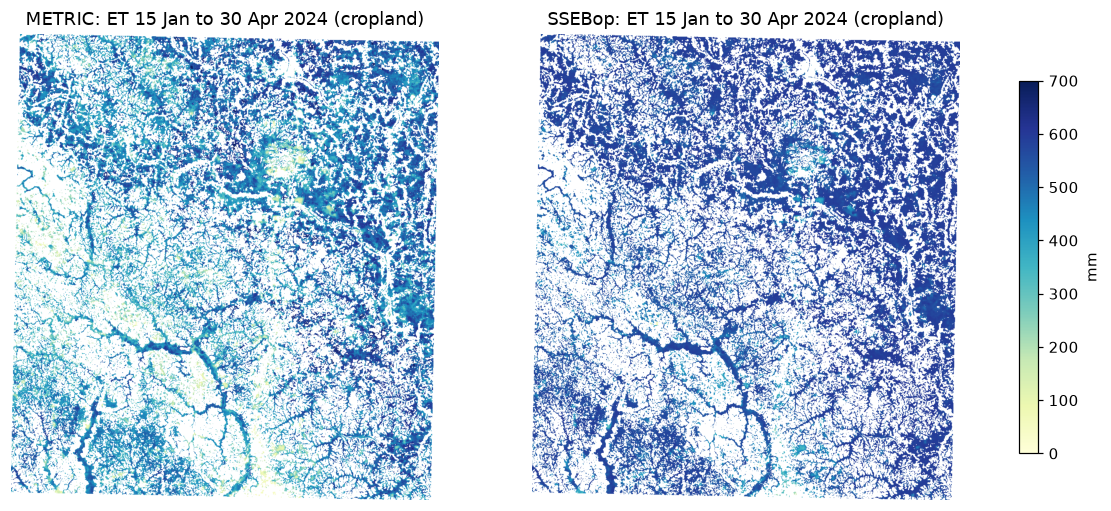

In [7]:
start, end = "2024-01-15", "2024-04-30"  # Boro season
days = pd.date_range(start, end)  # every day
etr = ref["etr"].loc[start:end]  # daily ETr
ke_d = xr.DataArray(ke.reindex(days).values, coords={"time": days}, dims="time")  # daily Ke
ke_i = ke.reindex(pd.DatetimeIndex(etrf.time.values)).reindex(days.union(pd.DatetimeIndex(etrf.time.values))).interpolate("time").ffill().bfill().reindex(days)  # Ke as the images see it
corr = xr.DataArray((ke.reindex(days) - ke_i).values, coords={"time": days}, dims="time")  # daily minus interpolated soil evaporation
fc_d = seb.interpolate_etrf(fc, start=start, end=end, max_gap_days=None, clip=(0, 1))  # daily cover
models = {"METRIC": etrf, "SSEBop": etf}  # the two models
season_et = {}  # seasonal ET maps
for name, cube in models.items():  # both models
    dly = seb.interpolate_etrf(cube, start=start, end=end, max_gap_days=None)  # daily fraction
    dly = (dly + (1 - fc_d) * corr).clip(0, 1.3)  # rain adjustment of the bare part
    season_et[name] = seb.seasonal_et(dly, etr)  # mm, 15 January to 30 April
tab = pd.DataFrame({name: {"rice mean (mm)": float(v.where(rice).mean()), "rice p10 (mm)": float(v.where(rice).quantile(0.1)),
                           "rice p90 (mm)": float(v.where(rice).quantile(0.9)), "other cropland mean (mm)": float(v.where(crop & ~rice).mean())}
                    for name, v in season_et.items()}).T  # per model
tab["reference ETr (mm)"] = float(etr.sum()); tab["reference ETo (mm)"] = float(ref["eto"].loc[start:end].sum())  # references
tab["rain (mm)"] = float(rain.loc[start:end].sum())  # rain
display(tab.round(0))  # table
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))  # two maps
for a_, (name, v) in zip(ax, season_et.items()):  # both models
    im = a_.imshow(v.where(crop), cmap="YlGnBu", vmin=0, vmax=700); a_.set_title(f"{name}: ET 15 Jan to 30 Apr 2024 (cropland)"); a_.axis("off")  # map
plt.colorbar(im, ax=ax, shrink=0.8, label="mm"); plt.show()  # shared scale

## Crop coefficients of rice

The median ETrF of the rice pixels on each image, converted to the grass basis (`Kc = ETrF ETr/ETo`),
can be compared with FAO-56's rice coefficients: about 1.05 at the start, 1.20 in mid-season and
0.90 to 0.60 at the end (Table 12). FAO-56 assumes flooded rice from the start, with the water
surface evaporating at close to the reference rate.

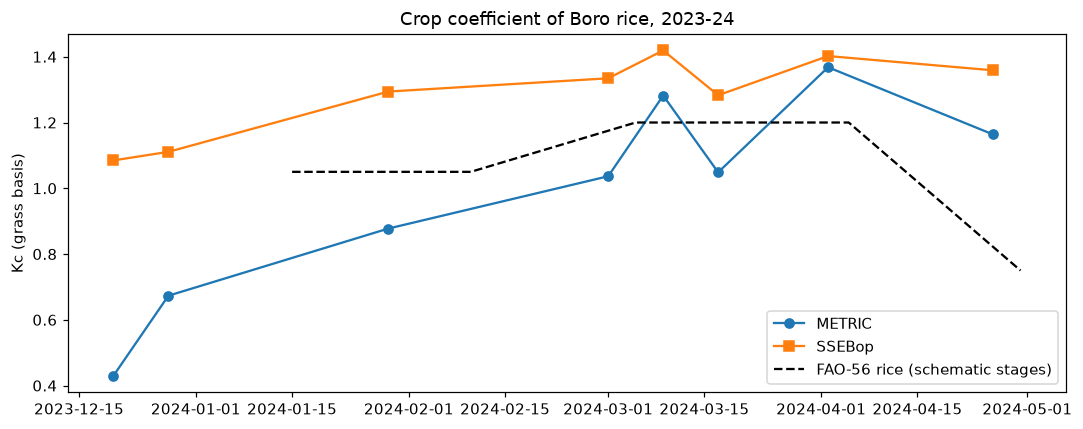

,METRIC,SSEBop
2023-12-20,0.43,1.08
2023-12-28,0.67,1.11
2024-01-29,0.88,1.29
2024-03-01,1.04,1.33
2024-03-09,1.28,1.42
2024-03-17,1.05,1.28
2024-04-02,1.37,1.40
2024-04-26,1.16,1.36


In [8]:
ratio = (ref["etr"] / ref["eto"]).reindex(pd.DatetimeIndex(etrf.time.values))  # ETr/ETo on the image dates
kc = pd.DataFrame({"METRIC": etrf.where(rice).median(["y", "x"]).values * ratio.values,
                   "SSEBop": etf.where(rice).median(["y", "x"]).values * ratio.values}, index=pd.DatetimeIndex(etrf.time.values))  # grass-basis Kc
fig, ax = plt.subplots(figsize=(10, 4))  # one panel
ax.plot(kc.index, kc.METRIC, "o-", label="METRIC"); ax.plot(kc.index, kc.SSEBop, "s-", label="SSEBop")  # satellite Kc
fao = pd.Series([1.05, 1.05, 1.20, 1.20, 0.75], index=pd.to_datetime(["2024-01-15", "2024-02-10", "2024-03-05", "2024-04-05", "2024-04-30"]))  # FAO-56 rice, schematic stages
ax.plot(fao.index, fao.values, "k--", label="FAO-56 rice (schematic stages)")  # tabulated curve
ax.set_ylabel("Kc (grass basis)"); ax.legend(); ax.set_title("Crop coefficient of Boro rice, 2023-24"); plt.tight_layout(); plt.show()  # draw
kc.round(2)  # table

## From millimetres to water volume

Seasonal ET times the rice area is the water the crop consumed. It is less than the water pumped:
paddies also lose water by percolation to the aquifer and seepage through the bunds, much of which
returns to groundwater, and by surface drainage.

In [9]:
vol = {name: float(v.where(rice).sum()) / 1000 * 900 for name, v in season_et.items()}  # m3 consumed, per model
for name, v in vol.items():  # both models
    print(f"{name}: {v / 1e6:.0f} million m3 over {area_ha:,.0f} ha of Boro rice "
          f"({v / area_ha:,.0f} m3/ha, {float(season_et[name].where(rice).mean()):.0f} mm)")  # volume
print(f"rain on the rice area in the same period: {float(rain.loc[start:end].sum()) / 1000 * area_ha * 1e4 / 1e6:.0f} million m3")  # rain

METRIC: 102 million m3 over 20,614 ha of Boro rice (4,941 m3/ha, 494 mm)
SSEBop: 119 million m3 over 20,614 ha of Boro rice (5,749 m3/ha, 575 mm)
rain on the rice area in the same period: 14 million m3


## Discussion

**What the result says.** METRIC gives Boro rice 494 mm of ET between mid-January and the end of
April (10th to 90th percentile 406 to 575 mm) and SSEBop 575 mm, against 69 mm of rain and an
alfalfa reference ET of 568 mm. Over 20,600 ha that is 100 to 120 million m3 consumed, against 14
million m3 of rain on the same area, so the
difference must come from irrigation (groundwater). The ET is the consumptive part of that
irrigation. Pumping is larger: the percolation and seepage losses of puddled paddies are commonly
of the same order as ET, and much of them recharges the aquifer, which is why consumptive use, not
pumping, is the right quantity for a basin's water budget.

**How the models compare.** METRIC and SSEBop share the thermal signal but differ in their limits:
METRIC calibrates both ends on two pixels of each image, SSEBop sets them from air temperature and
radiation. In a low-contrast humid scene METRIC depends heavily on finding a representative hot
anchor; SSEBop depends on the `c` factor and on ERA5's maximum temperature over a 25 km cell. Their
difference is a measure of model uncertainty for this landscape, as in notebook 11.

**What limits accuracy.**

- **Mixed pixels.** Fields of 0.05 to 0.5 ha mean that many 30 m pixels (and every 100 m thermal
  pixel) mix rice with bunds, homesteads and trees. The rice map excludes some of them; the ET of
  the remainder is a blend.
- **Haze and cloud.** The dry season is the clearest part of the year, yet only eight images were
  usable, with gaps of about a month between 28 December and 29 January and between 29 January and
  1 March, right through transplanting. Each missing image widens the interpolation.
- **Anchors.** The cold pool is dominated by homestead trees early in the season and by rice later;
  the hot pool by settlements and roads, whose low ET is not that of dry soil.
- **Reference ET.** ERA5 is the only weather source here; local stations of the Bangladesh
  Meteorological Department would allow a check of its humidity and wind.
- **No ground truth.** There is no flux tower in the area. Rice ET measured with lysimeters or
  flux towers elsewhere in South Asia, and the FAO-56 coefficients, are the available benchmarks.

**Scaling up.** The same chain runs for any upazila or for the whole country: the WRS-2 tiles of
Bangladesh, Sentinel-2 with sharpened Sentinel-3 or Landsat thermal data (notebook 09) to fill the
gaps, and the Department of Agricultural Extension's Boro areas to check the rice map. Year-to-year
comparisons then show how consumptive use responds to changes in area, sowing dates and weather.

## Summary and exercises

- Boro rice was mapped from its transplanting flood (LSWI above NDVI) and March green-up within
  WorldCover cropland.
- Seasonal ET from mid-January to April was 494 mm (METRIC) to 575 mm (SSEBop); over the 20,600 ha
  of rice that is 100 to 120 million m3 of consumptive use, against 14 million m3 of rain.
- METRIC's rice crop coefficient rose from 0.88 in late January to 1.04 to 1.37 from March, around
  FAO-56's 1.20; SSEBop's stayed near its cap on every date.
- The anchors were only 2.5 to 10 K apart, which makes humid, smallholder landscapes far more
  sensitive to anchor choice than the California site.

**Exercises**

1. Change the flood test to `LSWI + 0.1 >= NDVI` and the green threshold to 0.5. How sensitive is
   the rice area, and the total volume?
2. Restrict METRIC's cold pool to rice pixels (`landcover=rice.astype(int)`, `cold_classes=[1]`).
   Do the early season ETrF values change?
3. Extend the analysis to the 2022-23 Boro season and compare the two years.
4. Replace the 30 m Landsat thermal data with Sentinel-3 LST sharpened with Sentinel-2 (notebook 09)
   for a date in the January gap. How much does an extra image change the seasonal total?